In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from sklearn.model_selection import train_test_split
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])
print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (2507, 41)
Whales: <StringArray>
[ 'W-1', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17',
 'W-18', 'W-19',  'W-2', 'W-20', 'W-21', 'W-22', 'W-23', 'W-24',  'W-3',
  'W-4',  'W-5',  'W-6',  'W-7',  'W-8',  'W-9']
Length: 24, dtype: str


In [3]:
FEATURES = [
    'ltv',
    'ltv_lag_1',
    'ltv_lag_3',
    'ltv_lag_7',
    'ltv_vol_7d',
    'ltv_vol_14d',
    'distance_to_liq',
    'health_factor',
    'carry_spread',
    'carry_spread_levered',
    'loop_depth'
]

TARGET = 'rebalancing'

print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())

Features: 11
Target: rebalancing

Target distribution:
rebalancing
0    2136
1     371
Name: count, dtype: int64


**We use 11 features:**

- `ltv`, `ltv_lag_1`, `ltv_lag_3`, `ltv_lag_7`: the current leverage ratio and its past values
- `ltv_vol_7d`, `ltv_vol_14d`: how much the leverage has been moving around recently
- `distance_to_liq`: how far the position is from being liquidated
- `health_factor`: the overall risk score from the protocol
- `carry_spread`, `carry_spread_levered`: the yield earned minus the cost of borrowing
- `loop_depth`: how many times the position has been looped

**We left out 3 features to avoid data leakage:**

`rebal_freq_7d`, `rebal_freq_30d`, and `days_since_rebalance` are all built directly from the rebalancing column, which is the thing we are trying to predict. Using them would let the model cheat by peeking at the answer.

In [4]:
data = df.dropna(subset=FEATURES)

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} Rebalancing rate: {y_train.mean():.1%}')
print(f'Test: {X_test.shape}  Rebalancing rate: {y_test.mean():.1%}')

Train: (1032, 11) Rebalancing rate: 14.6%
Test: (443, 11)  Rebalancing rate: 14.7%


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.94      0.79      0.86       378
           1       0.36      0.69      0.48        65

    accuracy                           0.78       443
   macro avg       0.65      0.74      0.67       443
weighted avg       0.85      0.78      0.80       443

ROC-AUC: 0.828


**Logistic Regression Baseline Results**

We run Logistic Regression first as a simple baseline before XGBoost.

**Reading the results:**

Accuracy is 78%, meaning the model gets 78% of days right overall. But accuracy alone can be misleading here, since most days are not rebalancing days, so it is more useful to look at how well the model finds the rebalancing days specifically.

Recall for rebalancing is 0.69, so the model catches 69% of the actual rebalancing days and misses the other 31%.

Precision for rebalancing is 0.36, so when the model predicts a rebalancing day, it is only correct 36% of the time. This means it also flags a lot of false alarms, days it thinks are rebalancing but are not.

ROC-AUC is 0.828, which shows a fairly good general ability to tell rebalancing days apart from normal days.

Overall, the baseline catches most rebalancing events, but it also raises a lot of false alarms. This gives us a benchmark. XGBoost needs to beat these numbers, especially precision, to justify the added complexity.

In [11]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,  # shallower trees
    learning_rate=0.05,  # slower learning
    subsample=0.8,  # use 80% of rows per tree
    colsample_bytree=0.8,  # use 80% of features per tree
    min_child_weight=5,  # need at least 5 samples per leaf
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print('=== XGBoost ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]):.3f}')

scale_pos_weight: 5.83
=== XGBoost ===
              precision    recall  f1-score   support

           0       0.94      0.83      0.88       378
           1       0.41      0.71      0.52        65

    accuracy                           0.81       443
   macro avg       0.68      0.77      0.70       443
weighted avg       0.87      0.81      0.83       443

ROC-AUC: 0.876


**XGBoost Model and Results**

The scale_pos_weight of 5.83 tells XGBoost that non-rebalancing days outnumber rebalancing days by about 6 to 1. This stops the model from being lazy and just predicting 0 every time.

**Key settings explained simply:**

n_estimators is 50, so the model builds 50 decision trees.
max_depth is 2, so each tree is shallow. This stops the model from memorizing the training data.
learning_rate is 0.05, so the model learns slowly and carefully.
subsample is 0.8, so each tree only sees 80% of the rows. This adds variety between trees.
colsample_bytree is 0.8, so each tree only uses 80% of the features. This helps reduce overfitting.
min_child_weight is 5, so a group needs at least 5 samples before it can be split further. This stops the model from making tiny, meaningless splits.

---

**Results compared to the baseline:**

| Metric | Logistic Regression | XGBoost |
|---|---|---|
| Recall (rebalancing) | 0.69 | 0.71 |
| Precision (rebalancing) | 0.36 | 0.41 |
| ROC-AUC | 0.828 | 0.876 |

XGBoost is better across all three numbers. It catches slightly more rebalancing days (recall of 0.71 versus 0.69), it is right more often when it predicts a rebalancing day (precision of 0.41 versus 0.36), and it is noticeably better at telling rebalancing days apart from normal days overall (ROC-AUC of 0.876 versus 0.828).

In short, XGBoost improves on every measure here. It is not a huge jump, but it is a real one, and it comes without giving up anything compared to the baseline.

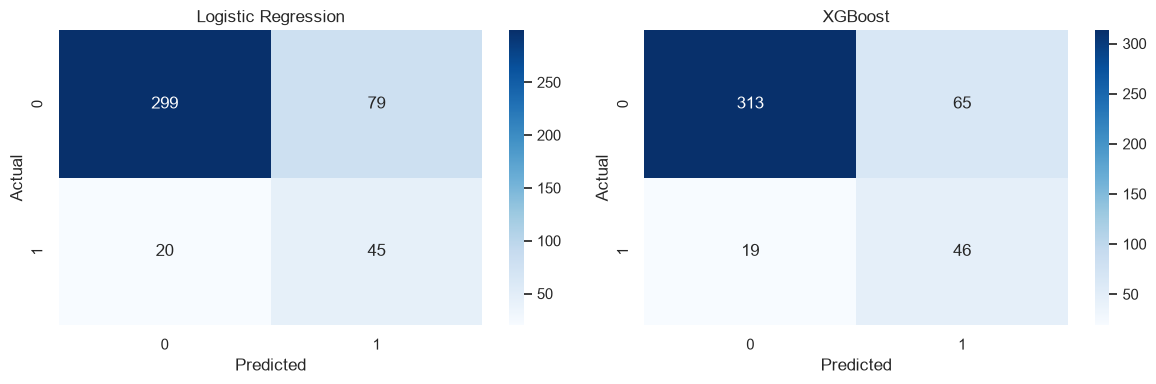

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, preds, title in zip(axes,
                            [y_pred_lr, y_pred_xgb],
                            ['Logistic Regression', 'XGBoost']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Confusion Matrix Rebalancing Model**

Each matrix shows 4 numbers. Reading them:

Top left: correctly predicted no rebalancing (true negatives)
Top right: predicted rebalancing but was wrong (false alarms)
Bottom left: missed actual rebalancing days (missed events)
Bottom right: correctly predicted rebalancing (true positives)

---

**Logistic Regression:**

Correctly caught 45 out of 65 rebalancing days.
Missed 20 rebalancing days.
Made 79 false alarms.

**XGBoost:**

Correctly caught 46 out of 65 rebalancing days.
Missed 19 rebalancing days.
Made 65 false alarms.

---

**What this means:**

XGBoost catches one more rebalancing day than Logistic Regression (46 versus 45) and also makes fewer false alarms (65 versus 79). So XGBoost is better on both counts here, not just a tradeoff. It misses slightly fewer real events and also raises fewer false alerts, which makes it the clearly stronger model of the two.

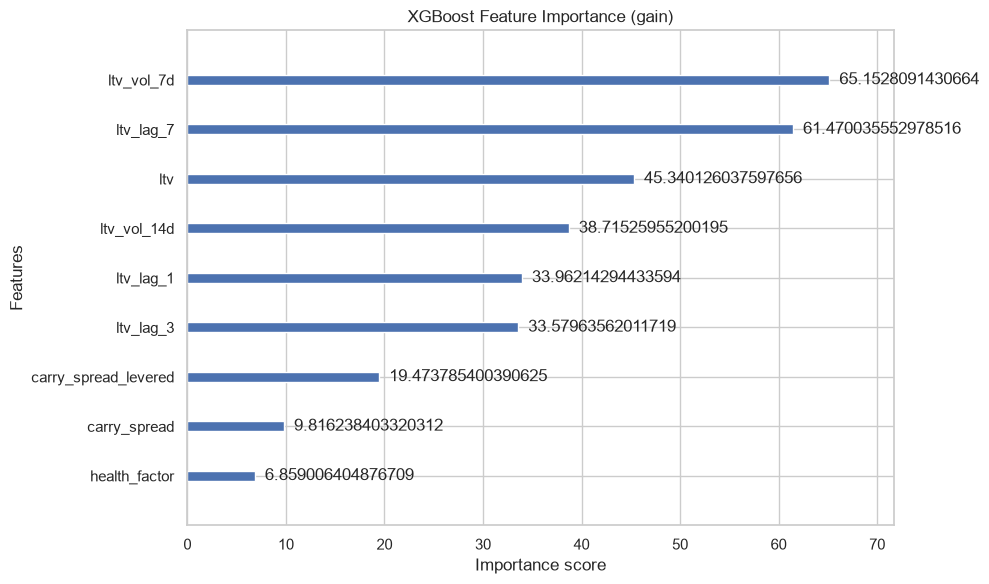

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=14, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain)')
plt.tight_layout()
plt.show()

This chart shows which features the model relied on most to predict rebalancing. A higher score means the feature was more useful for making predictions.

Note that only 9 of the 11 features show up here. This is because distance_to_liq and loop_depth were never used by any tree in the model, so XGBoost does not give them a score.

**Top features:**

ltv_vol_7d (65.2) is the most important feature by a small margin. This measures how much the leverage ratio has been moving around over the past 7 days. When leverage swings a lot in a short time, rebalancing becomes more likely.

ltv_lag_7 (61.5) is very close behind. This is what the leverage ratio was 7 days ago. This being so high tells us that whales seem to react to how leverage has built up over the past week, not just where it stands right now.

ltv (45.3) is the current leverage ratio itself, and it still matters a lot, just less than its own history.

ltv_vol_14d (38.7) shows that volatility over a longer 14 day window also plays a meaningful role, though slightly less than the shorter 7 day window.

ltv_lag_1 (34.0) and ltv_lag_3 (33.6) are close to each other. These are the leverage ratio from 1 day ago and 3 days ago. Together with ltv_lag_7, this shows that the model leans heavily on the recent history of leverage, not just a single point in time.

**Lower importance features:**

carry_spread_levered (19.5) and carry_spread (9.8) matter, but much less than the leverage related features. These measure the yield earned minus the borrowing cost.

health_factor (6.9) has the lowest importance of the group. This is a bit surprising since it is the main risk score in the protocol, but it seems the model finds more signal in the leverage numbers directly.

**Key finding:**

Rebalancing decisions seem to be driven mainly by leverage and how it has changed over time, rather than a single snapshot value. The fact that recent history (ltv_lag_7, ltv_lag_3, ltv_lag_1) and volatility (ltv_vol_7d, ltv_vol_14d) dominate the top of the chart suggests whales are reacting to a build up of risk over days, not just to how things look on any one day.

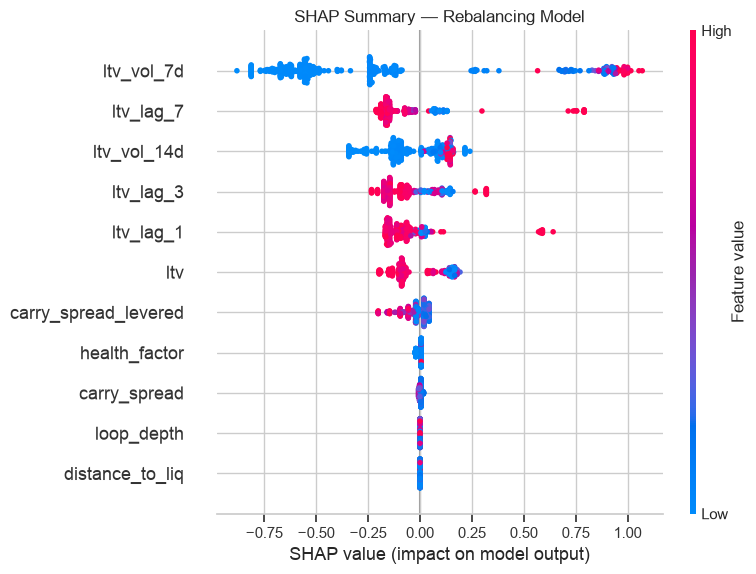

In [15]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Rebalancing Model')
plt.tight_layout()
plt.show()

SHAP Summary, Rebalancing Model

Each dot is one day in the test set. The position on the x-axis shows how much that feature pushed the prediction toward rebalancing (right side) or away from it (left side). The color shows the feature value: pink means high, blue means low.

ltv_vol_7d is the top feature and has the widest spread of any feature. Blue dots (low volatility) cluster tightly near zero, meaning stable leverage rarely leads to rebalancing. Pink and blue dots both stretch far in both directions, showing that this feature has the strongest overall pull on the model's predictions.

ltv_lag_7 is the second feature. Pink dots (high leverage 7 days ago) sit clearly to the right, pushing toward rebalancing. There are also a few pink dots that stretch far to the right, showing some days where old high leverage strongly predicted rebalancing.

ltv_vol_14d shows a similar pattern to ltv_vol_7d but with a smaller spread. This suggests that longer term leverage swings matter, but the more recent 7 day window has a bigger effect.

ltv_lag_3 and ltv_lag_1 both show pink dots clustered slightly left of center, with a mix of pink and blue dots spreading a bit to the right. This means recent leverage levels matter, but not as strongly or as clearly as the top three features.

ltv, the current leverage level, mostly shows pink dots slightly left and blue dots on the right, meaning higher current leverage does not push toward rebalancing as strongly as the leverage history features do.

carry_spread_levered, health_factor, carry_spread, loop_depth, and distance_to_liq all cluster tightly around zero. This means none of these features has much effect on the model's rebalancing predictions.

One thing worth noting is that distance_to_liq shows almost no spread at all, sitting right at zero. This lines up with what we saw in the feature importance chart, where distance_to_liq did not even appear because the model barely used it. This is a bit surprising since it is often thought of as a key risk signal, so it may be worth double checking how this feature was built or whether it is too correlated with other features like ltv.

Overall, the model relies mainly on leverage and how it has changed over the past 7 to 14 days, rather than the current leverage snapshot or yield related features. This supports the idea that whales react to a build up of risk over time, not just to how things look on any single day.

In [16]:
results = df.loc[X_test.index].copy()
results['pred_rebalancing'] = y_pred_xgb
results['pred_proba_rebalancing'] = xgb_model.predict_proba(X_test)[:, 1]
results[['whale_id', 'date', 'rebalancing', 'pred_rebalancing', 'pred_proba_rebalancing']].to_csv(
    'predictions_rebalancing.csv', index=False)
print('Saved: predictions_rebalancing.csv')

Saved: predictions_rebalancing.csv
